## <span style="color:purple"> Graph Yearly Temperature-Salinity Plots for Each MicroCAT </span>

<span style="color:purple"> These graphs will plot temperature against salinity data from across the year. The purpose of this is to visually inspect the composition of the water masses that are recorded at a particular MicroCAT, which should allow for some interpretation of their source. </span>

### <span style="color:purple"> Plotting function </span>

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Define global colour mapping for each year to ensure consistency across boreholes and MicroCATs
colours = {
    2001: "tab:blue",   2002: "tab:orange", 2003: "tab:green",
    2004: "tab:red",    2005: "tab:purple", 2006: "tab:brown",
    2007: "tab:pink",   2008: "tab:olive",  2009: "tab:cyan",
    2010: "darkblue",   2011: "crimson",    2012: "teal",
    2013: "goldenrod",
}

def plot_ts(df, borehole, cat, ylim_temp=None, xlim_sal=None):
    # Create a mask to filter the dataframe for the specified borehole and cat
    mask = (df["borehole"] == borehole) & (df["cat"] == cat)
    sub = df[mask].copy()
    
    # Extract year from the time column
    sub["year"] = sub["time"].dt.year

    # Extract the position of the iterated MicroCAT in the water column at its respective borehole
    position = sub["water_column_position"].iloc[0]

    # Get the unique years in the subset
    years = sorted(sub["year"].unique())

    # sharex=True to share the x-axis between the two subplots
    fig, ax = plt.subplots(1, 1, figsize=(10, 10), sharex=True)

    for year in years:
        # Filter the subset for the current year
        year_data = sub[sub["year"] == year]
        
        # Plot raw data
        ax.scatter(year_data["practical_salinity"], year_data["potential_temperature"], color=colours[year], label=str(year), s=2)
    
    ax.set_ylabel("Potential Temperature (°C)")
    ax.set_xlabel("Practical Salinity (PSS78)")
    ax.set_title(f"{borehole} {position.capitalize()} MicroCAT cat{cat}: Temperature vs. Salinity")

    ax.legend(ncols=3)

    if ylim_temp is not None: ax.set_ylim(*ylim_temp)
    if xlim_sal  is not None: ax.set_xlim(*xlim_sal)

    ax.grid(True)
    plt.tight_layout()
    plt.show()

### <span style="color:purple"> Plot yearly temperature vs. salinity plots for each borehole/cat </span>

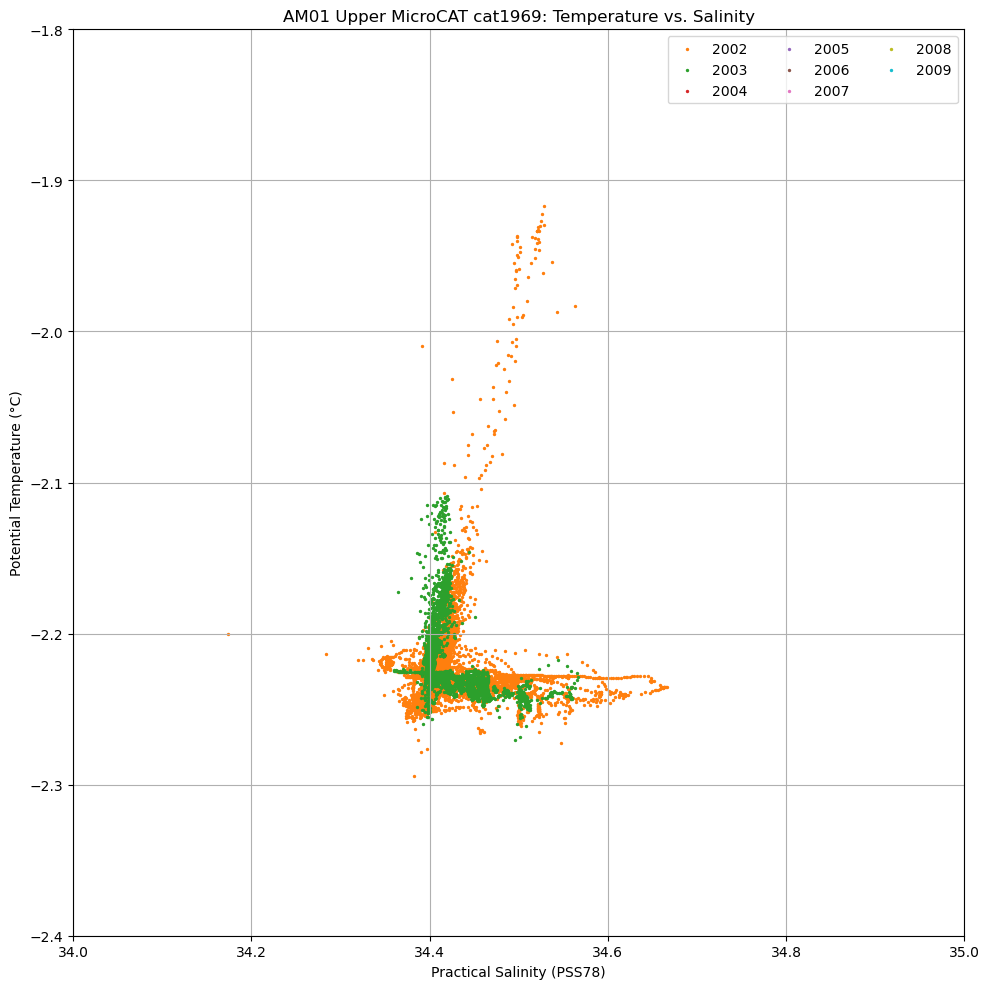

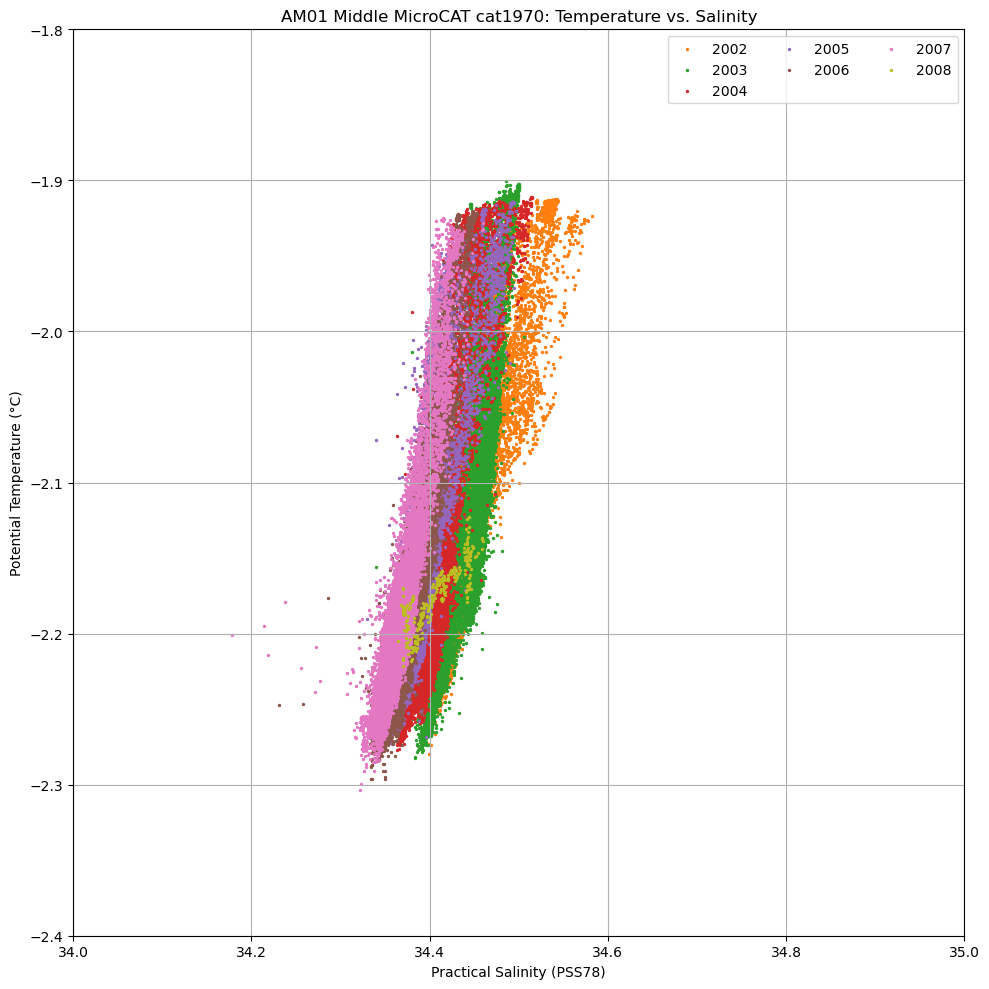

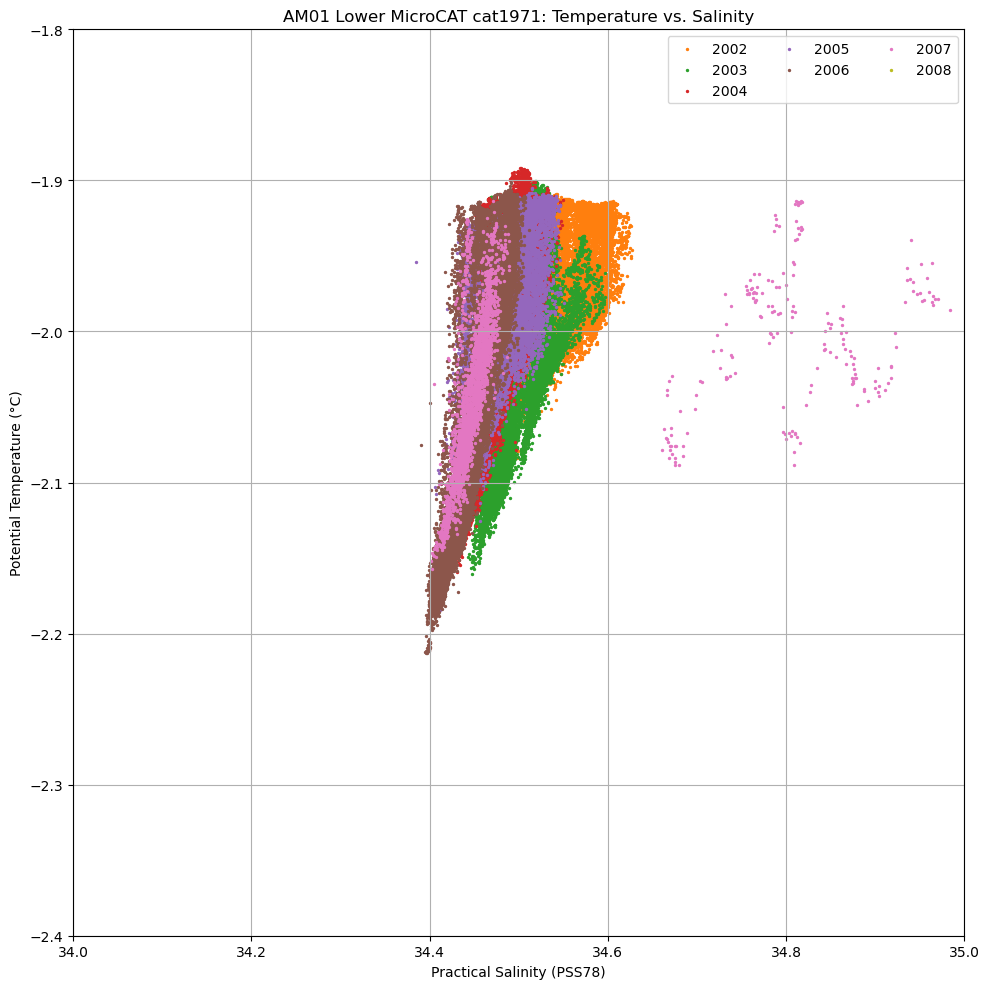

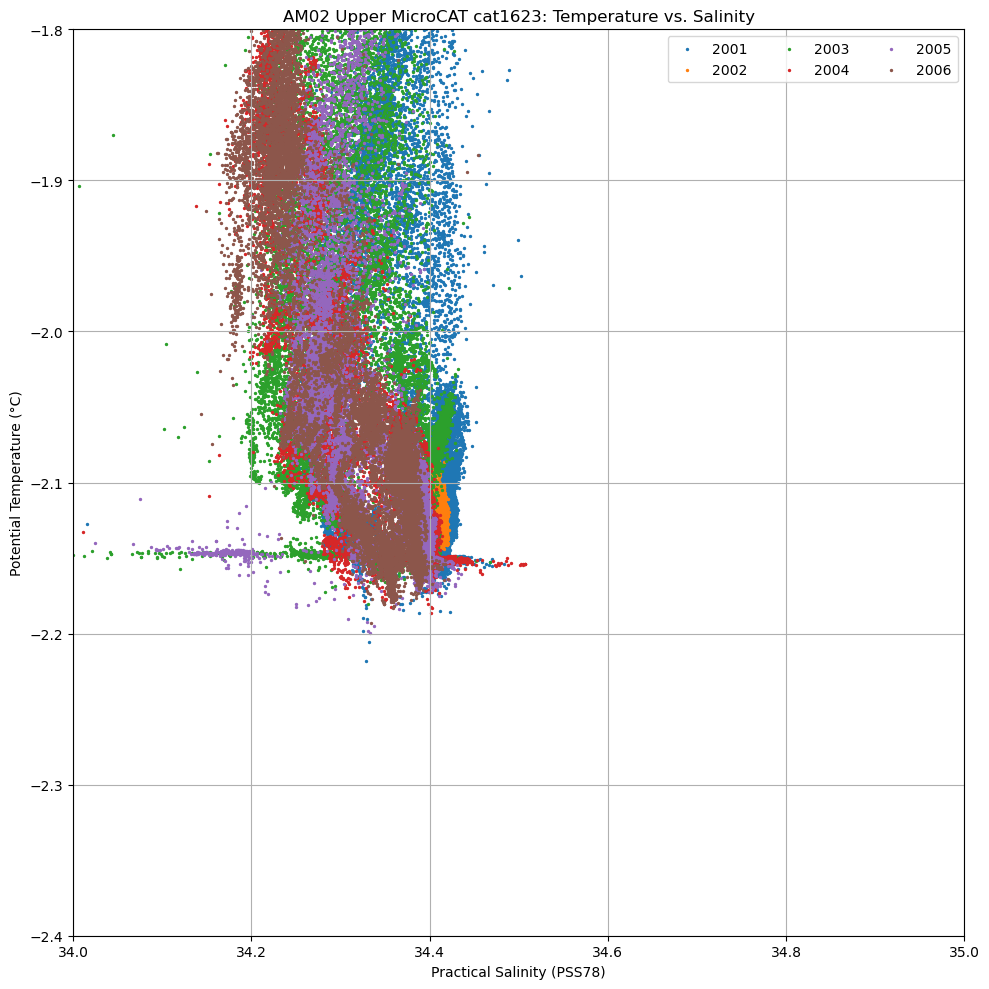

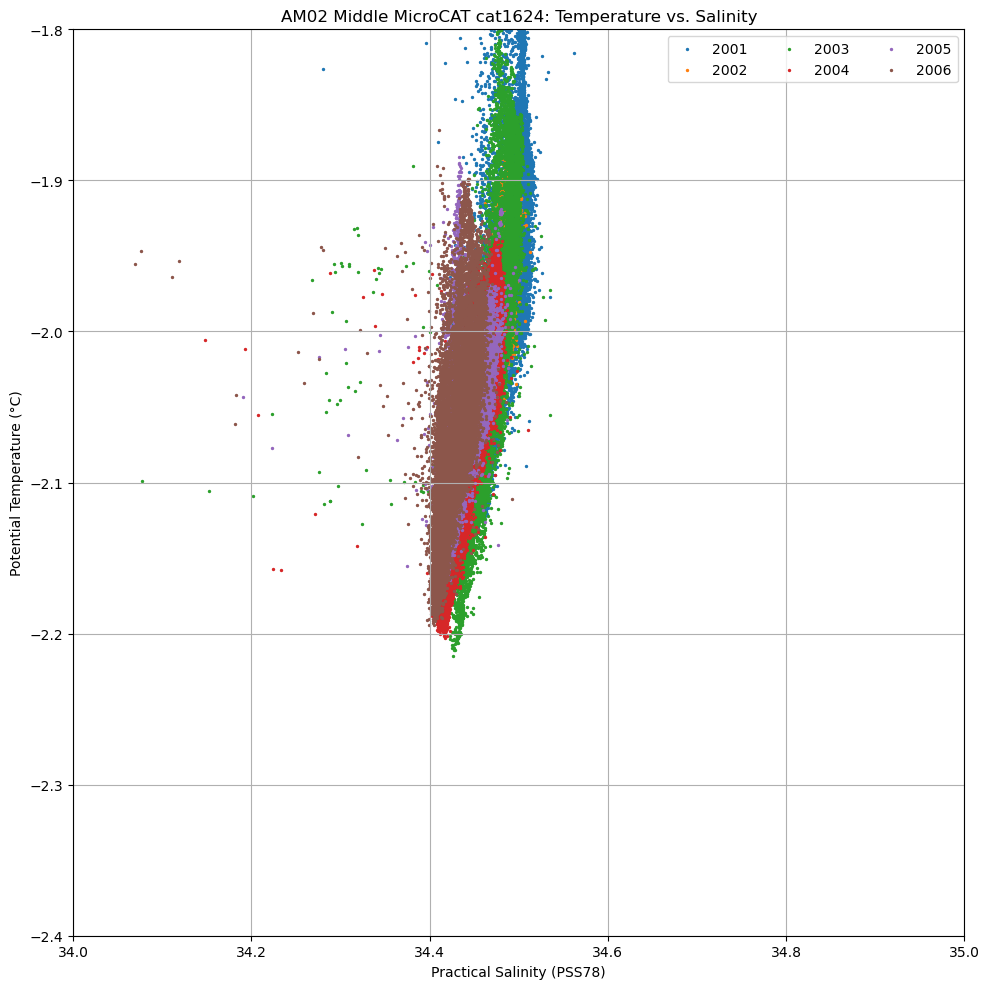

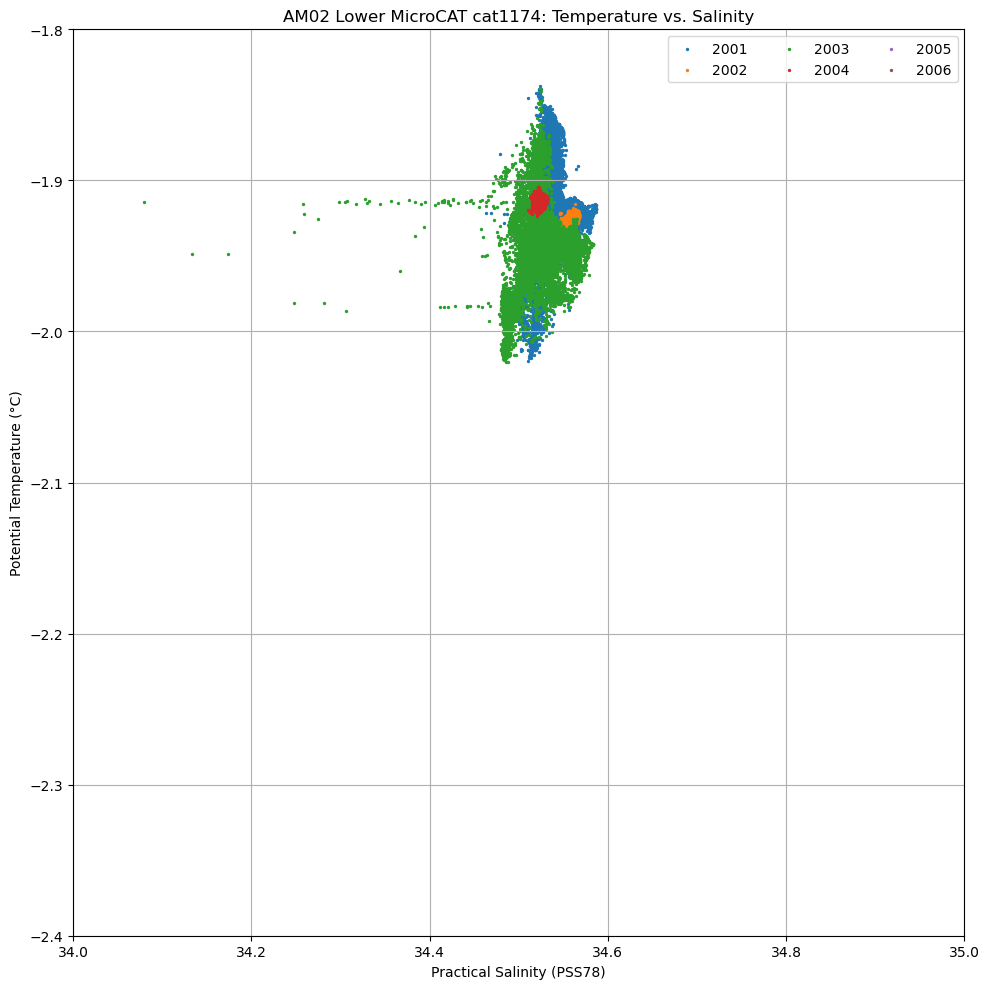

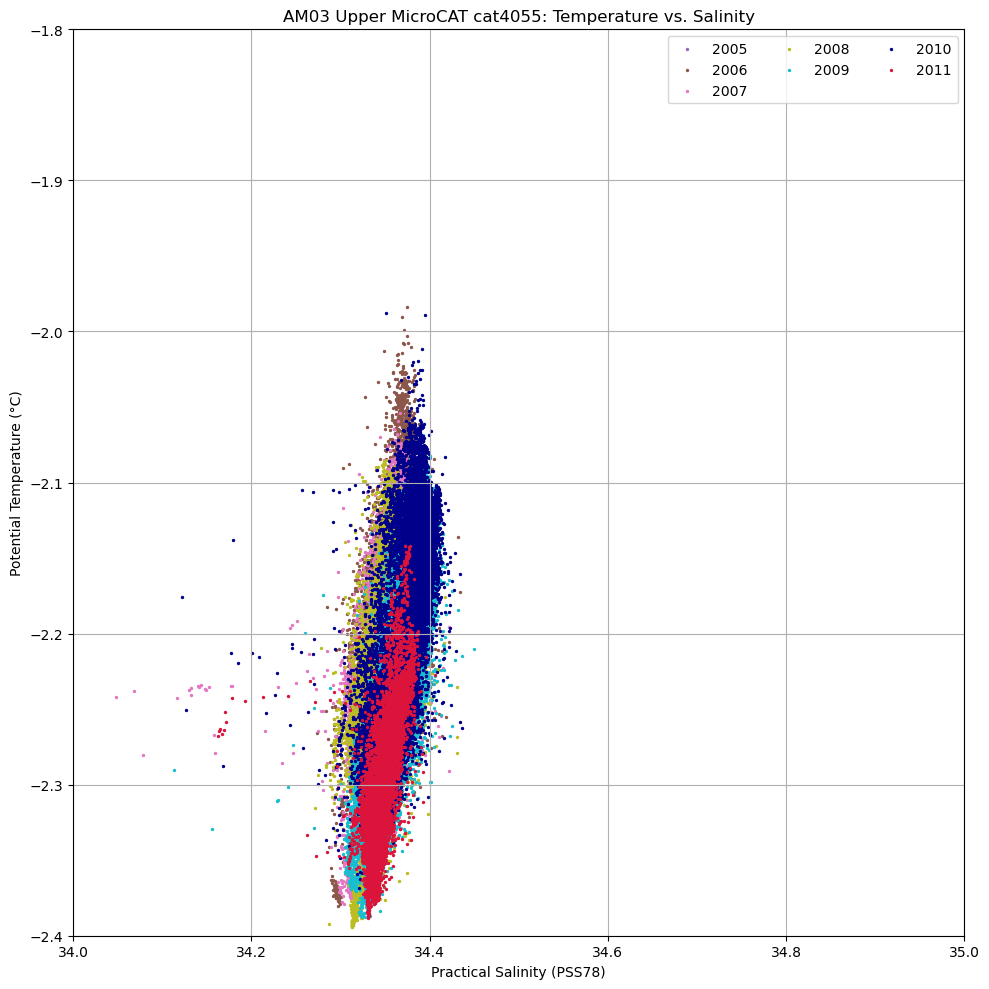

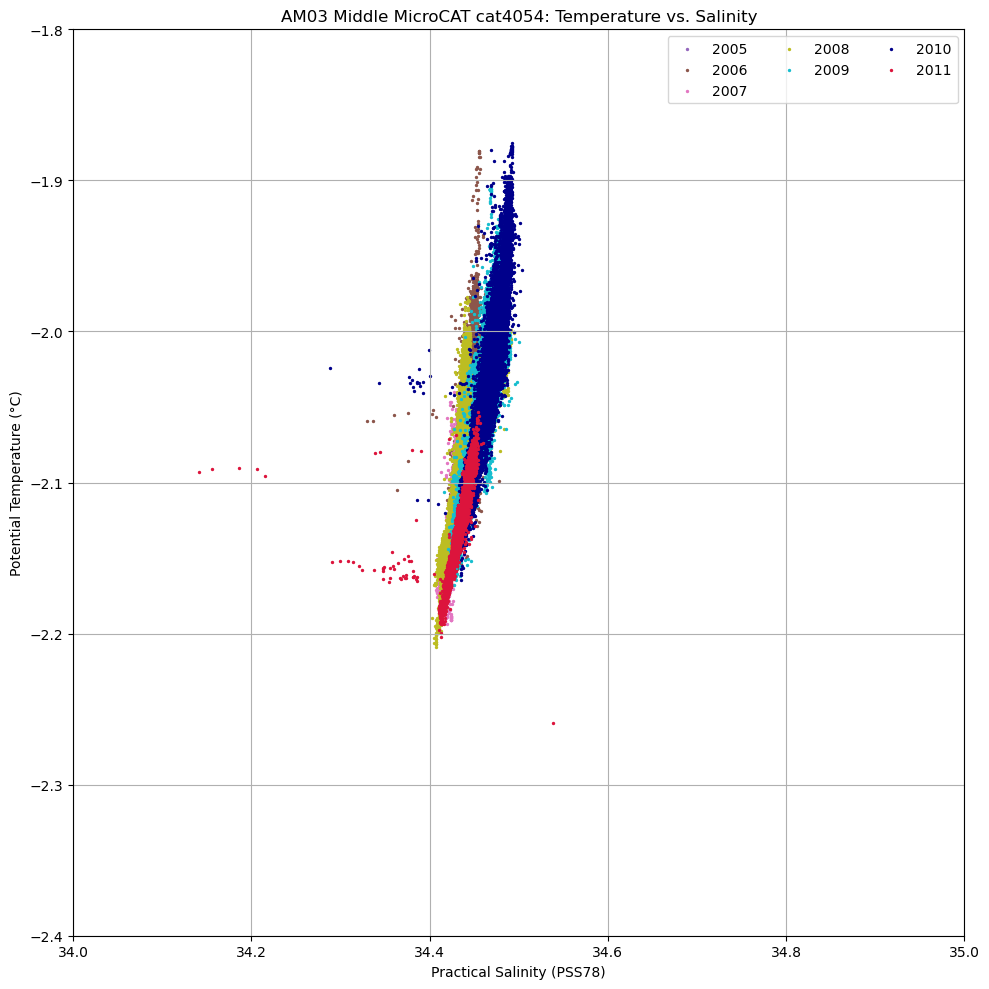

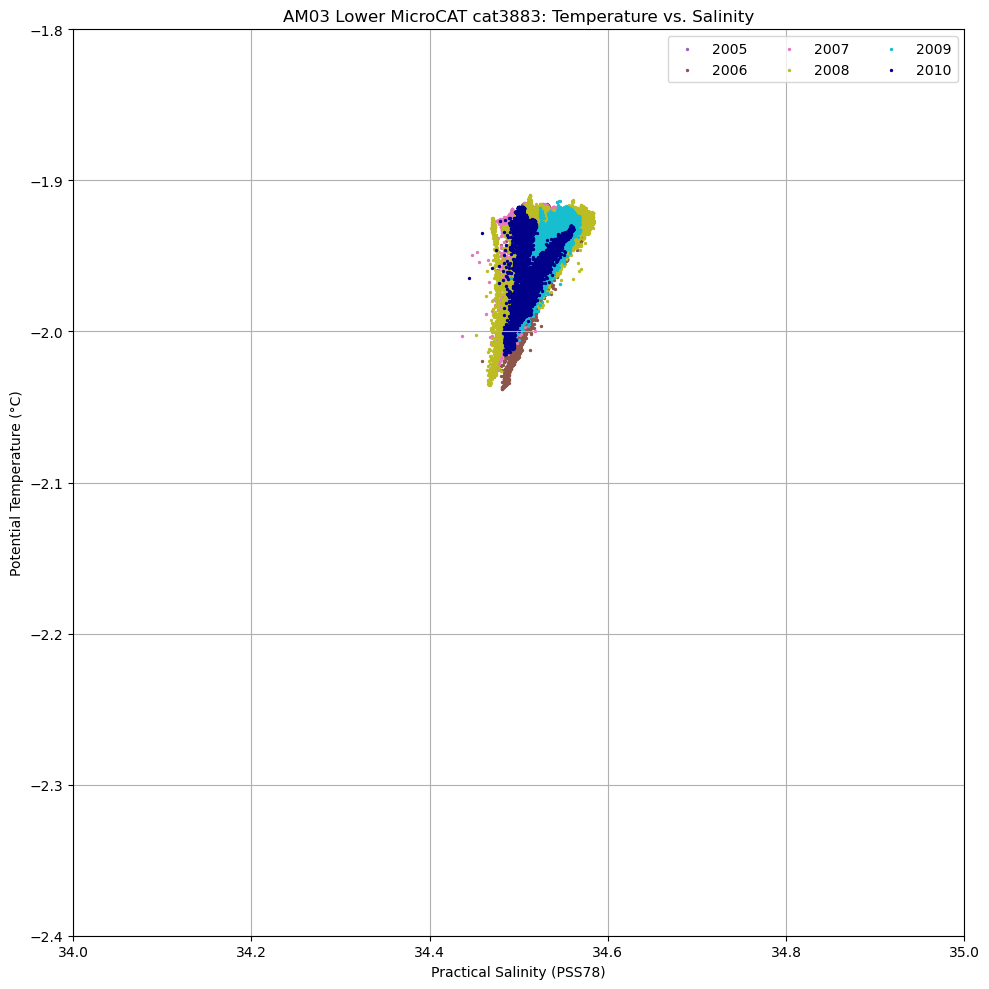

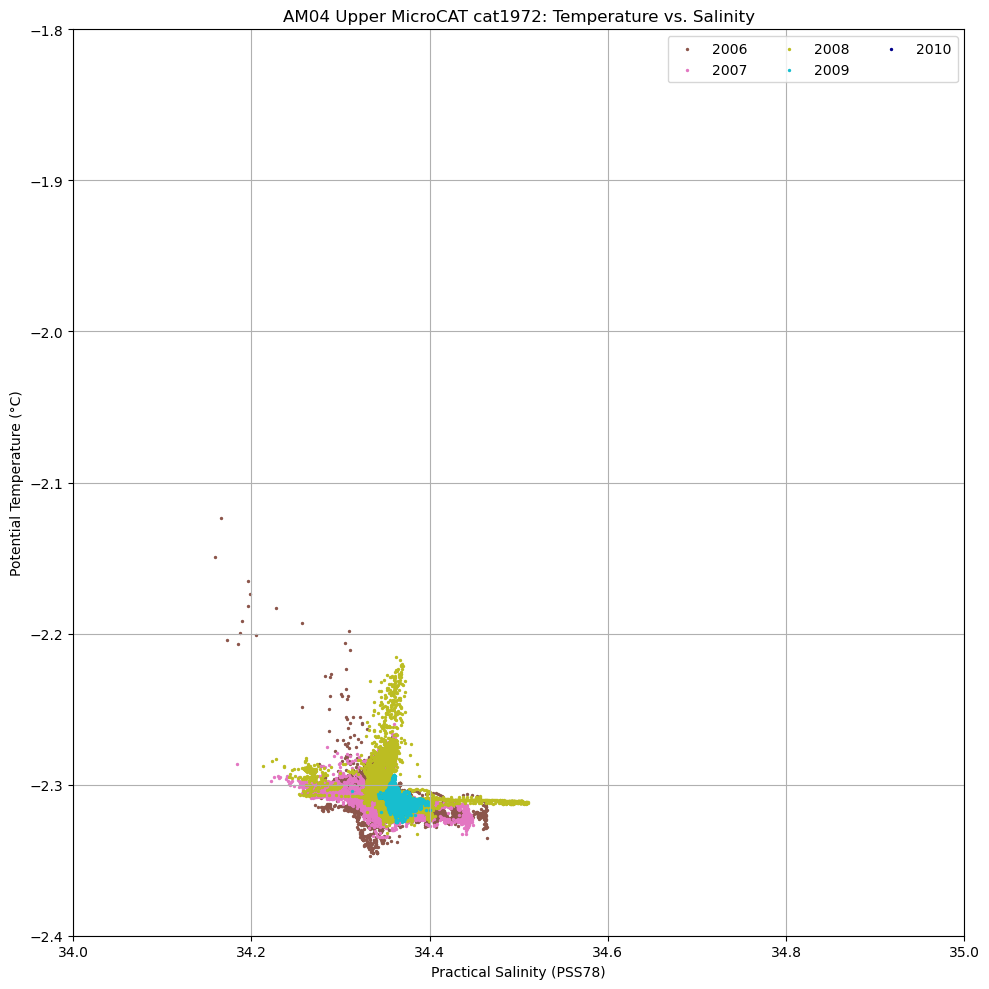

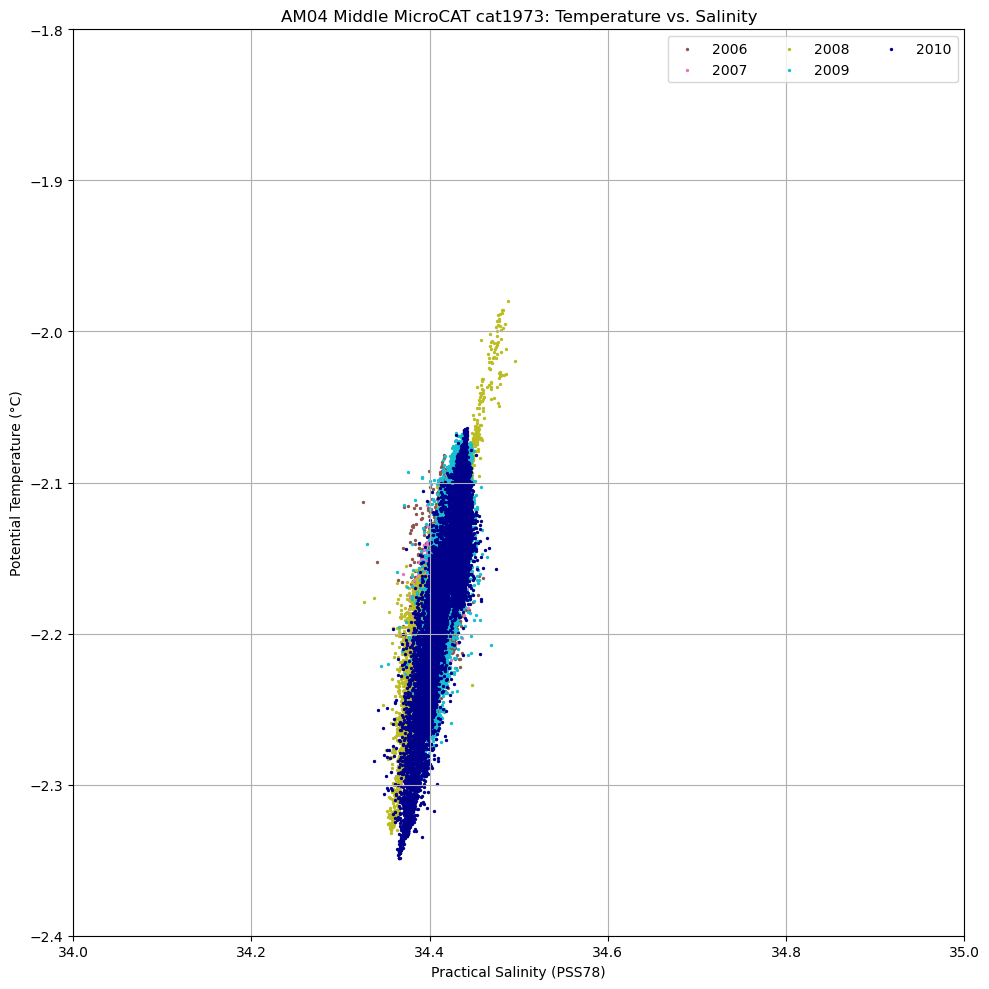

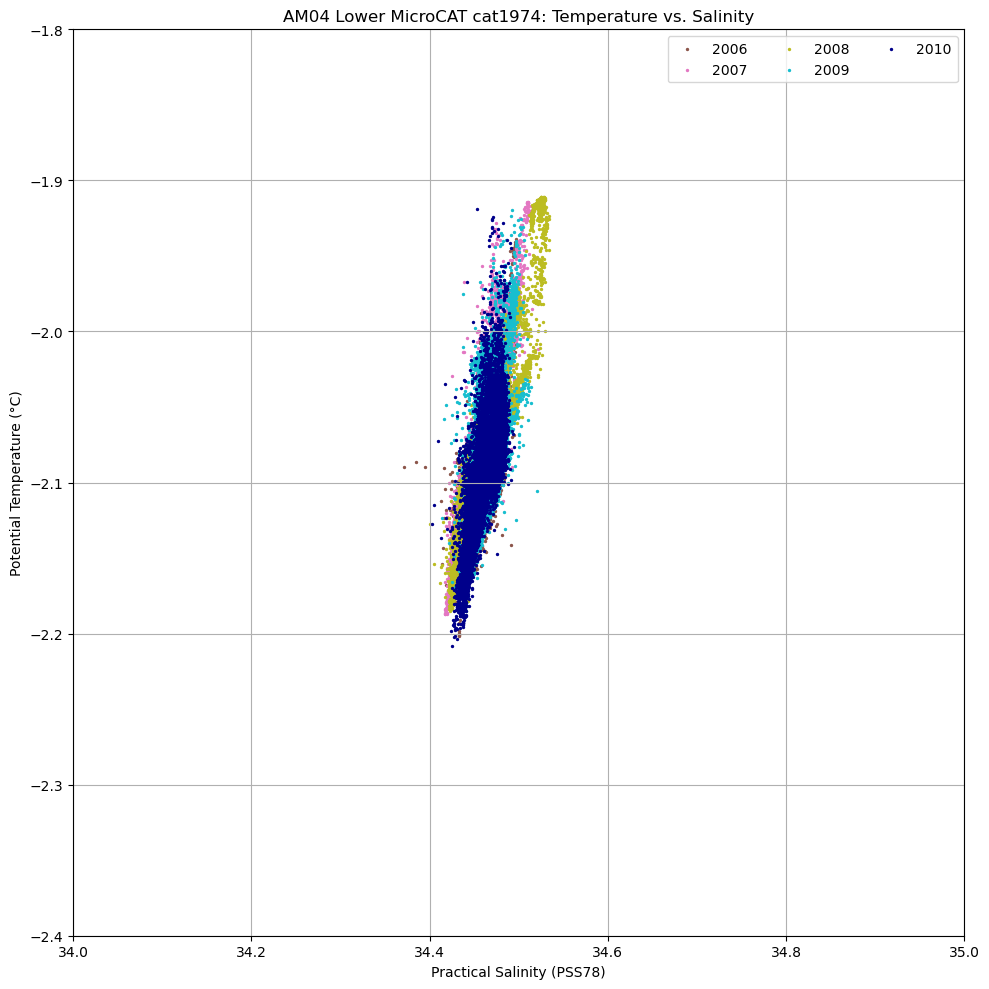

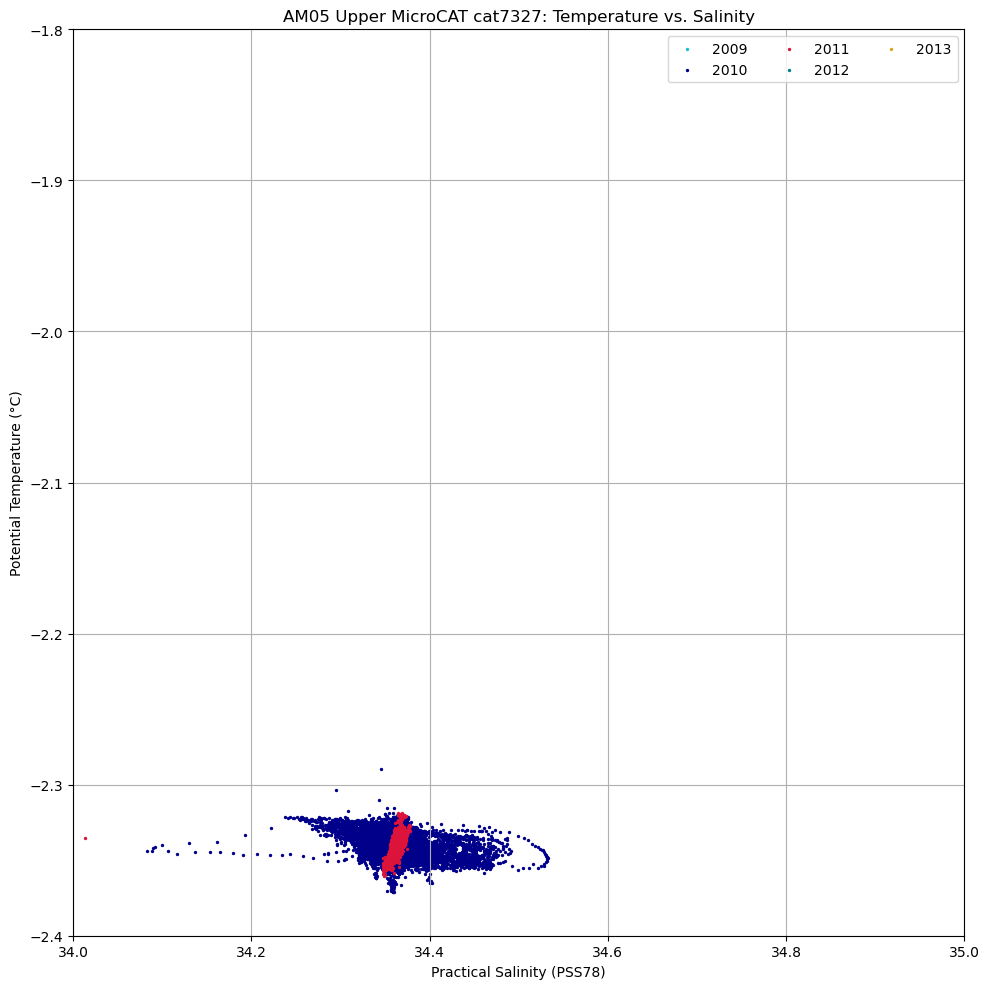

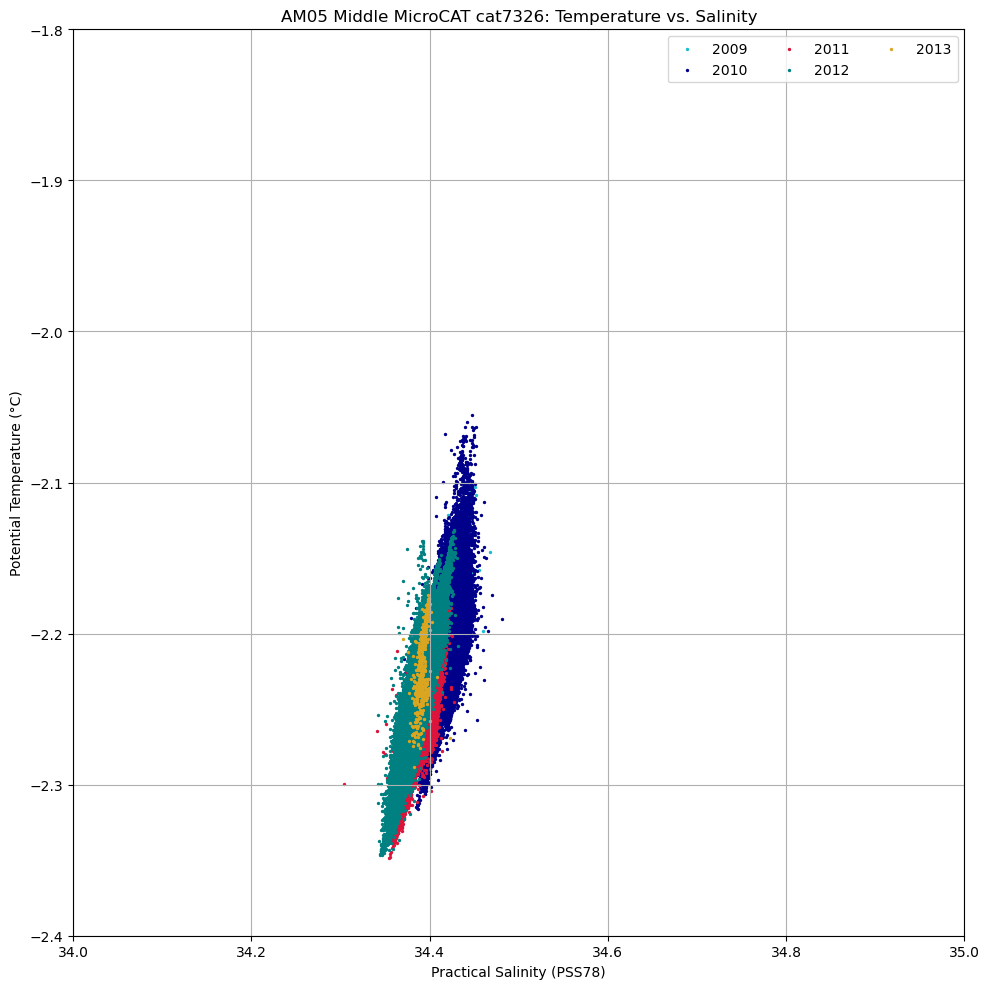

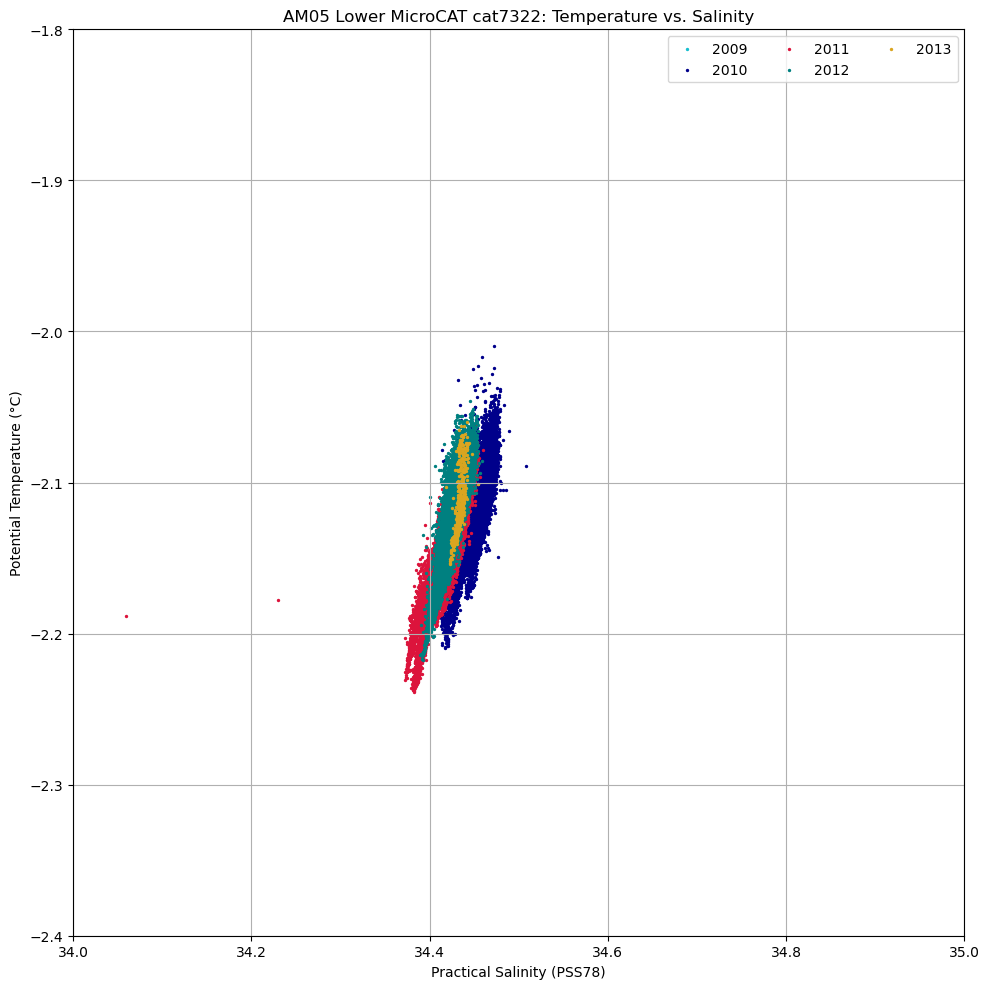

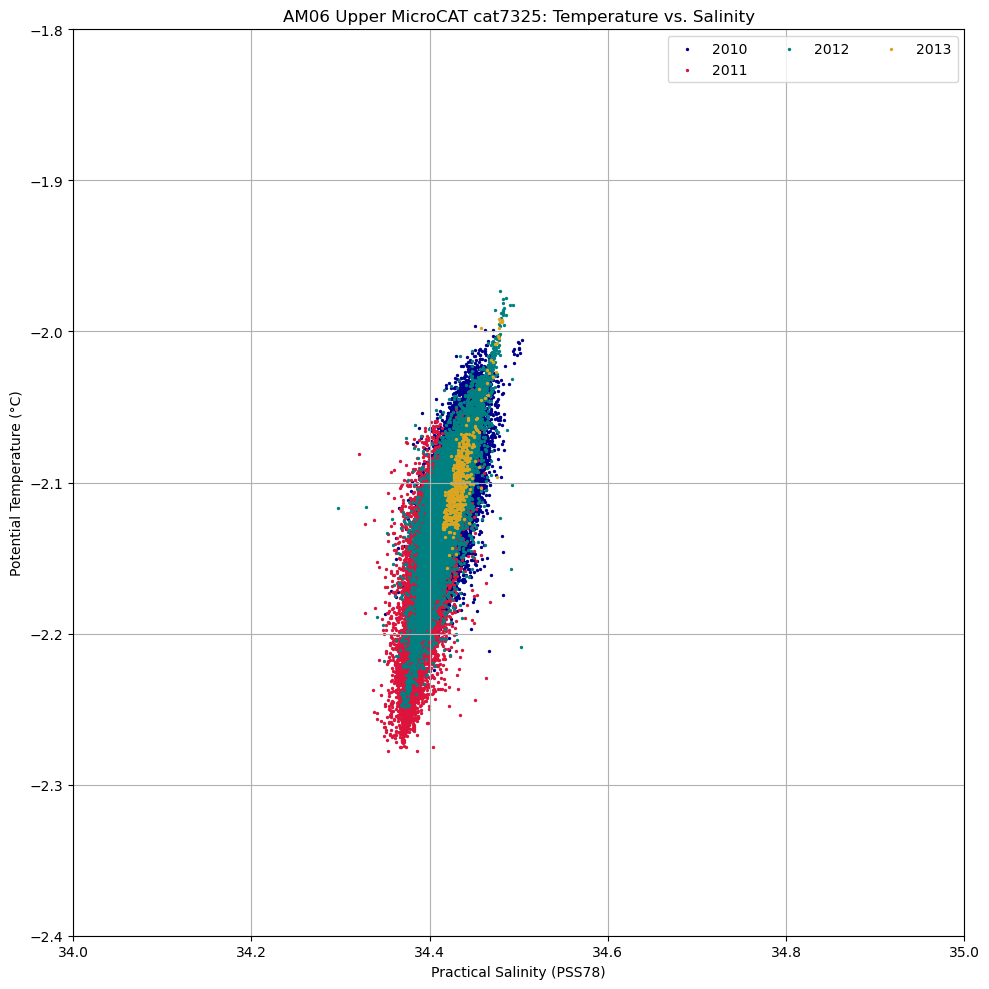

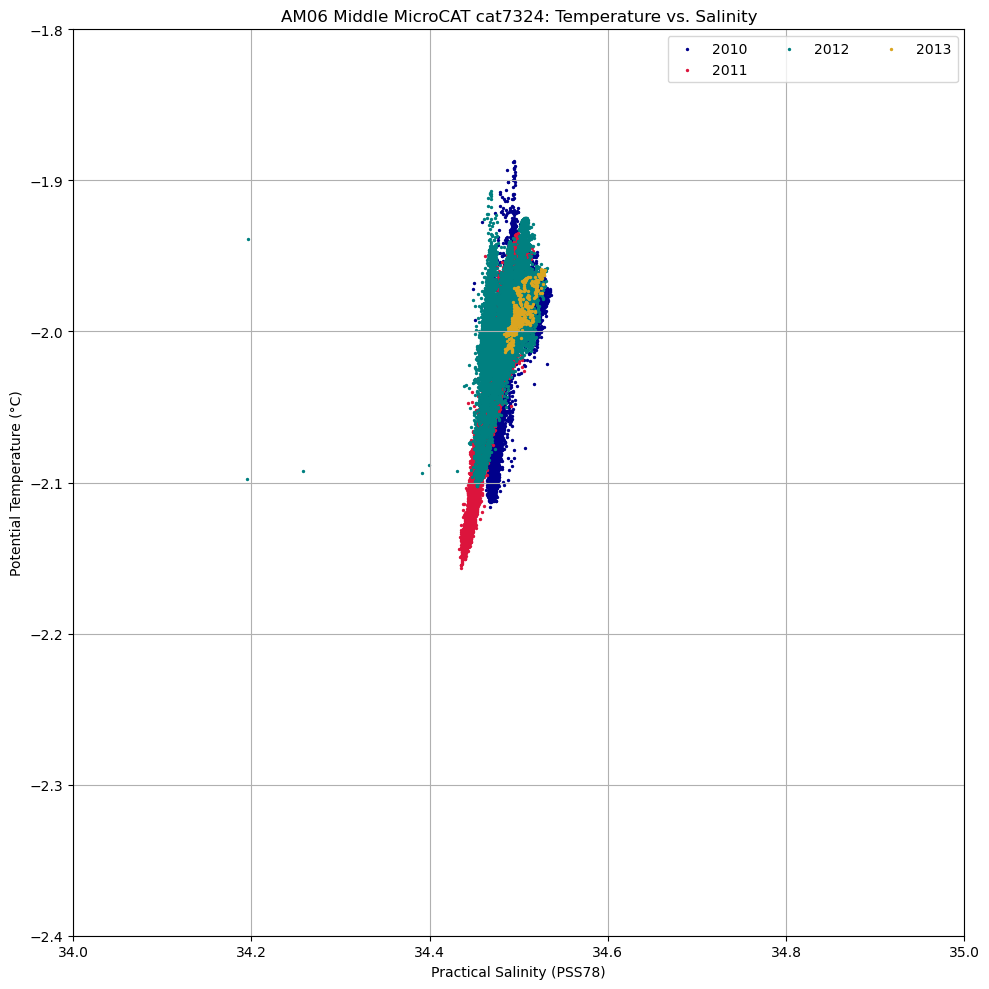

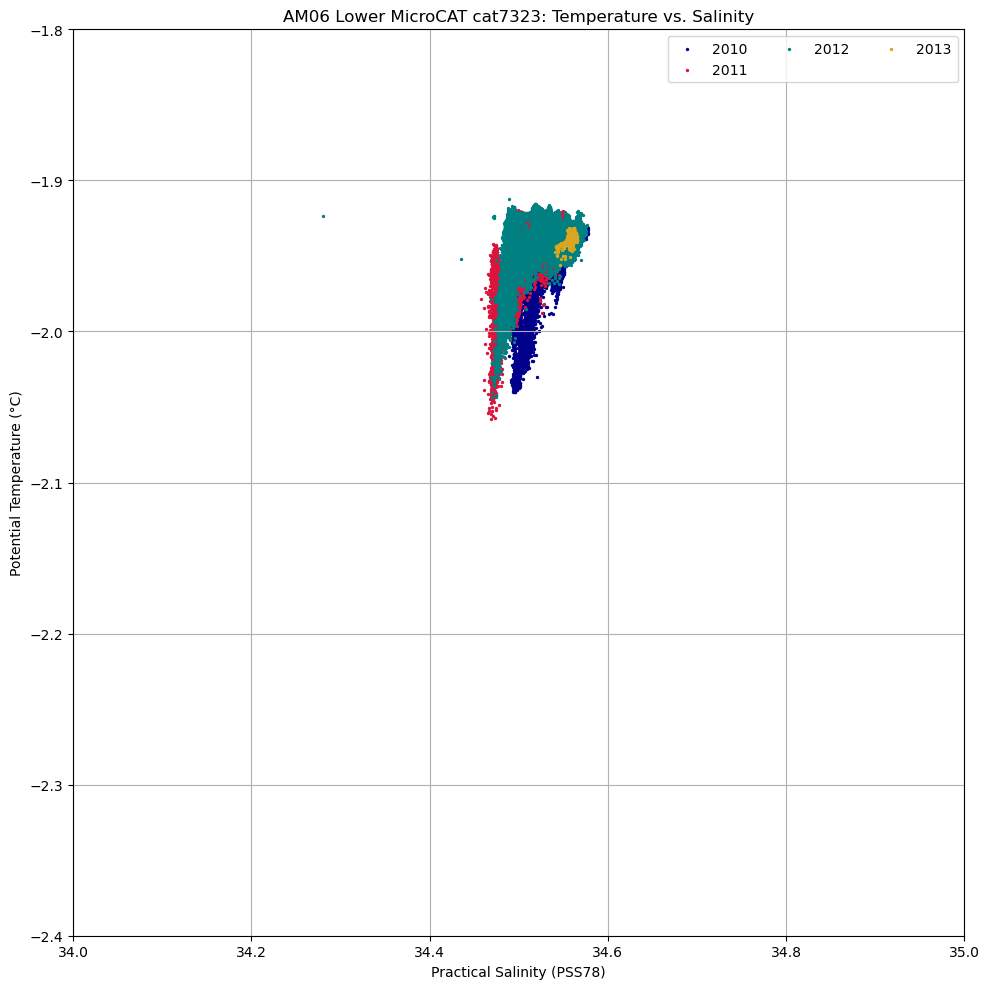

In [8]:
df = pd.read_parquet("../data/proc/03_pressure_handled.parquet")

# Define the limits for plots of temperature and salinity
ylim_temp = (-2.4, -1.8)
xlim_sal = (34, 35)

boreholes = sorted(df["borehole"].unique())

for borehole in boreholes:
    df_bh = df[df["borehole"] == borehole]

    # Build a list to force ordered plotting of the upper, then middle, then lower MicroCAT
    position_order = ["upper", "middle", "lower"]

    for position in position_order:
        cats = df_bh[df_bh["water_column_position"] == position]["cat"].unique()

        for cat in cats:
            plot_ts(df, borehole, cat, ylim_temp=ylim_temp, xlim_sal=xlim_sal)